In [1]:
# !pip install statsmodels
# !pip install gradio

# Predicting Appliance Energy Consumption in Households

The goal is to predict how much energy household appliances use (`Appliances`, in Wh) from indoor and outdoor temperature, humidity and weather readings. Better predictions help customers cut their bills and help the grid plan its load.

The data is 19,735 readings taken every 10 minutes. Because it is time-ordered, I split it by time instead of randomly, so the model never trains on the future.

## Imports

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              ExtraTreesRegressor, AdaBoostRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
px.defaults.template = 'plotly_white'
px.defaults.color_discrete_sequence = ['#2E86AB']

## Loading the data

In [3]:
df = pd.read_csv('energydata_complete.csv')
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y %H:%M')

print(df.shape)
print(df['date'].min(), 'to', df['date'].max())
df.head()

(19735, 29)
2016-01-11 17:00:00 to 2016-05-27 18:00:00


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [4]:
df.info()
print('missing values:', df.isnull().sum().sum())
print('duplicate rows:', df.duplicated().sum())
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[us]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7         19

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


`rv1` and `rv2` are just random numbers added to the dataset, so they carry no information about energy use. I drop them later.

The sensor columns come from different places in the house: `T1`/`RH_1` kitchen, `T2`/`RH_2` living room, `T3`/`RH_3` laundry room, `T4`/`RH_4` office, `T5`/`RH_5` bathroom, `T6`/`RH_6` outside the building (north side), `T7`/`RH_7` ironing room, `T8`/`RH_8` teenager room and `T9`/`RH_9` parents room. `T_out`, `Press_mm_hg`, `RH_out`, `Windspeed`, `Visibility` and `Tdewpoint` come from the Chièvres weather station. `lights` is the energy used by the light fixtures. `rv1` and `rv2` are just random numbers added to the dataset, so they carry no information about energy use. I drop them later.

## Train / validation / test split

I split by time: the first 70% of the rows for training, the next 15% for validation and the last 15% for testing. I do this before any cleaning or scaling so nothing is learned from validation or test data. The test set stays untouched until the final evaluation.

In [5]:
# sort by time first, so the split follows the calendar
df = df.sort_values('date').reset_index(drop=True)

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

for name, part in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(name, len(part), 'rows |', part['date'].min().date(), 'to', part['date'].max().date(),
          '| Appliances mean', round(part['Appliances'].mean(), 1))

train 13814 rows | 2016-01-11 to 2016-04-16 | Appliances mean 98.8
val 2960 rows | 2016-04-16 to 2016-05-07 | Appliances mean 93.4
test 2961 rows | 2016-05-07 to 2016-05-27 | Appliances mean 96.9


## Exploratory data analysis

I only look at the training data here, so nothing I learn about the validation or test period can influence my decisions.

#### A. Target: Appliances

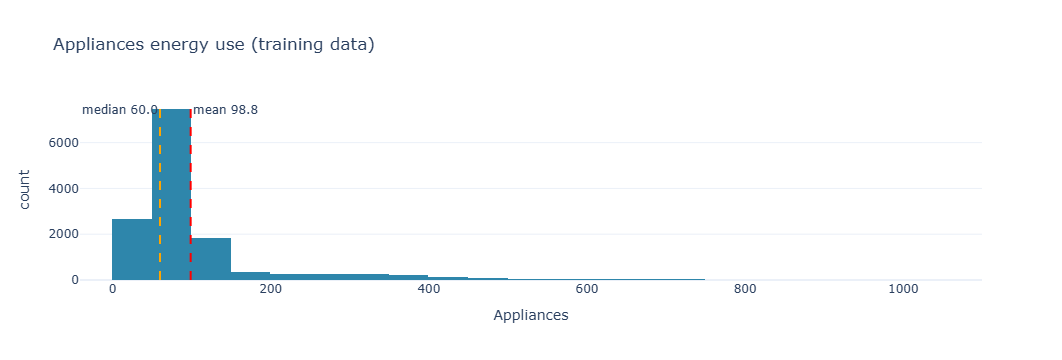

In [6]:
target = train_df['Appliances']

fig = px.histogram(train_df, x='Appliances', nbins=50,
                   title='Appliances energy use (training data)')
fig.add_vline(x=target.mean(), line_dash='dash', line_color='red',
              annotation_text=f'mean {target.mean():.1f}')
fig.add_vline(x=target.median(), line_dash='dash', line_color='orange',
              annotation_text=f'median {target.median():.1f}', annotation_position='top left')
fig.show()

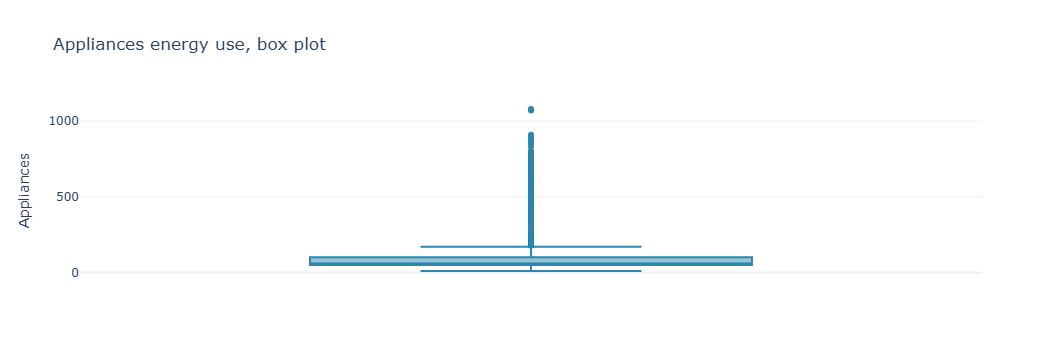

In [7]:
fig = px.box(train_df, y='Appliances', title='Appliances energy use, box plot')
fig.show()

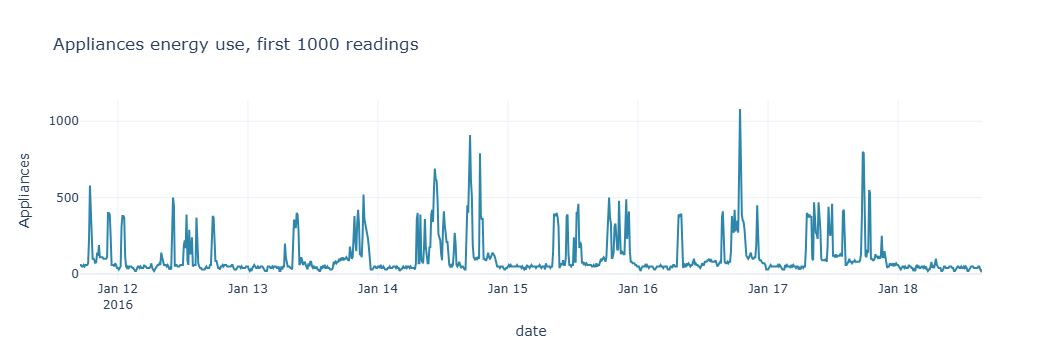

In [8]:
fig = px.line(train_df.head(1000), x='date', y='Appliances',
              title='Appliances energy use, first 1000 readings')
fig.show()

In [9]:
print('mean:', round(target.mean(), 1), '| median:', round(target.median(), 1),
      '| skew:', round(target.skew(), 2))

mean: 98.8 | median: 60.0 | skew: 3.25


Most readings are low (the median is 60 Wh), with a long tail of large spikes that pulls the mean up to about 99 Wh (skew 3.25). The spikes seem to repeat every day, so they look like normal household activity and not errors. I need to be careful about removing them as outliers later.

#### B. Feature distributions

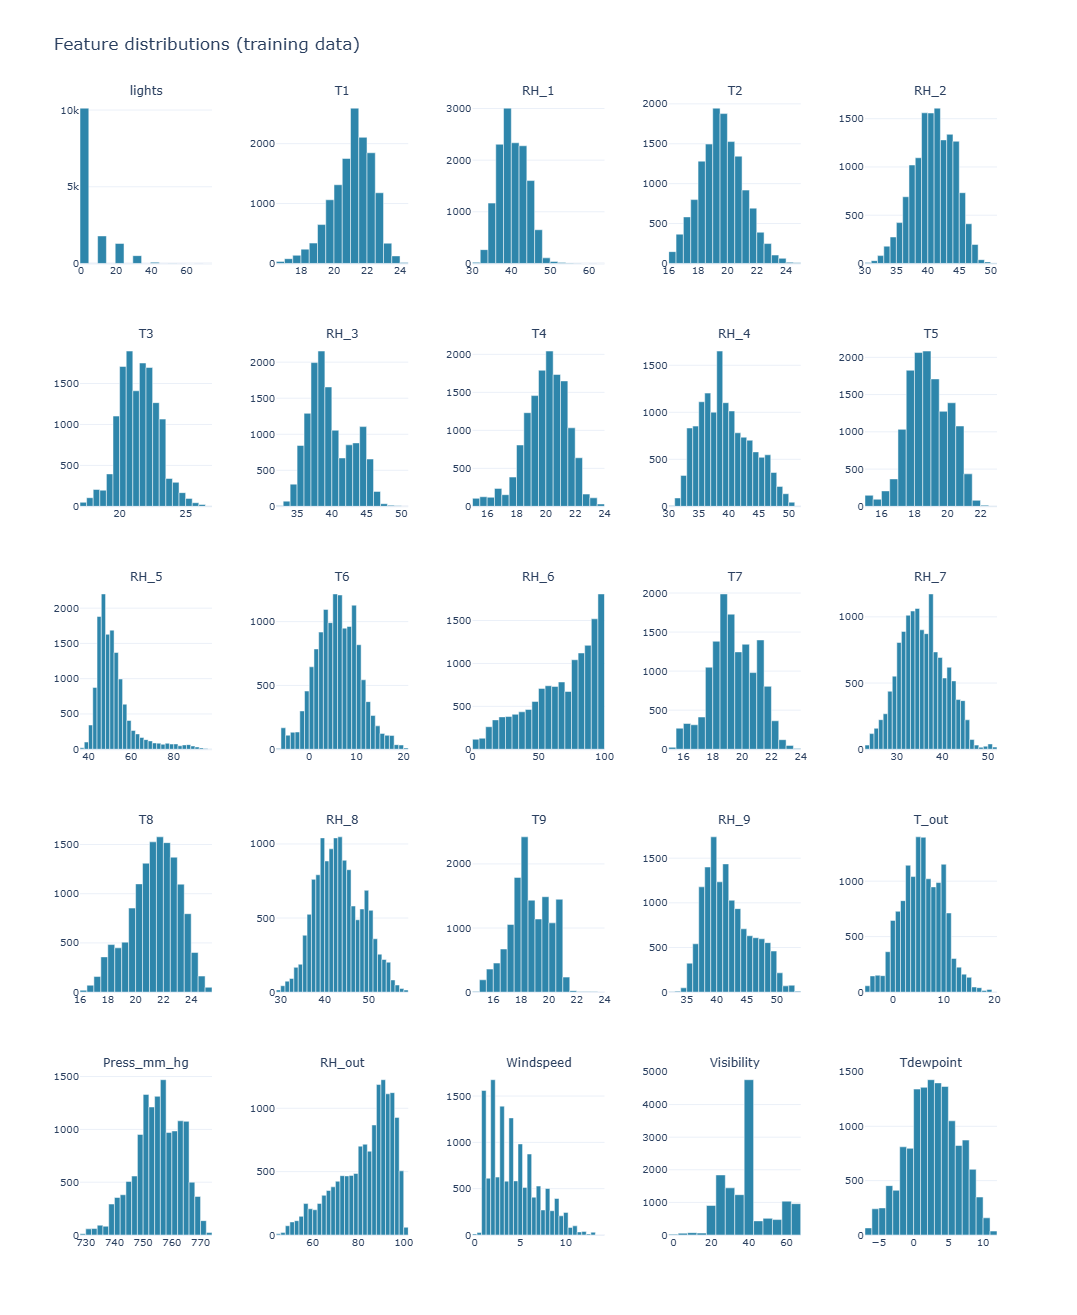

In [10]:
features = train_df.drop(columns=['date', 'Appliances', 'rv1', 'rv2'])

fig = px.histogram(features.melt(), x='value', facet_col='variable',
                   facet_col_wrap=5, nbins=30,
                   facet_col_spacing=0.07, facet_row_spacing=0.07,
                   width=1200, height=1300,
                   title='Feature distributions (training data)')
fig.update_traces(bingroup=None, marker_line_color='white', marker_line_width=0.5)
fig.update_xaxes(matches=None, showticklabels=True, title=None, tickfont_size=10)
fig.update_yaxes(matches=None, showticklabels=True, title=None, tickfont_size=10)
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=')[-1]))
fig.update_layout(showlegend=False)
fig.show()

In [11]:
skew = features.skew().round(2)
skew[skew.abs() > 1]

lights    1.95
RH_5      1.98
dtype: float64

Most temperature and humidity columns are roughly bell-shaped. Only `lights` (mostly 0) and `RH_5` (long right tail) are clearly skewed. `RH_6` and `RH_out` bunch up near 100, and `Visibility` has one value that appears far more often than any other.

#### C. Correlations

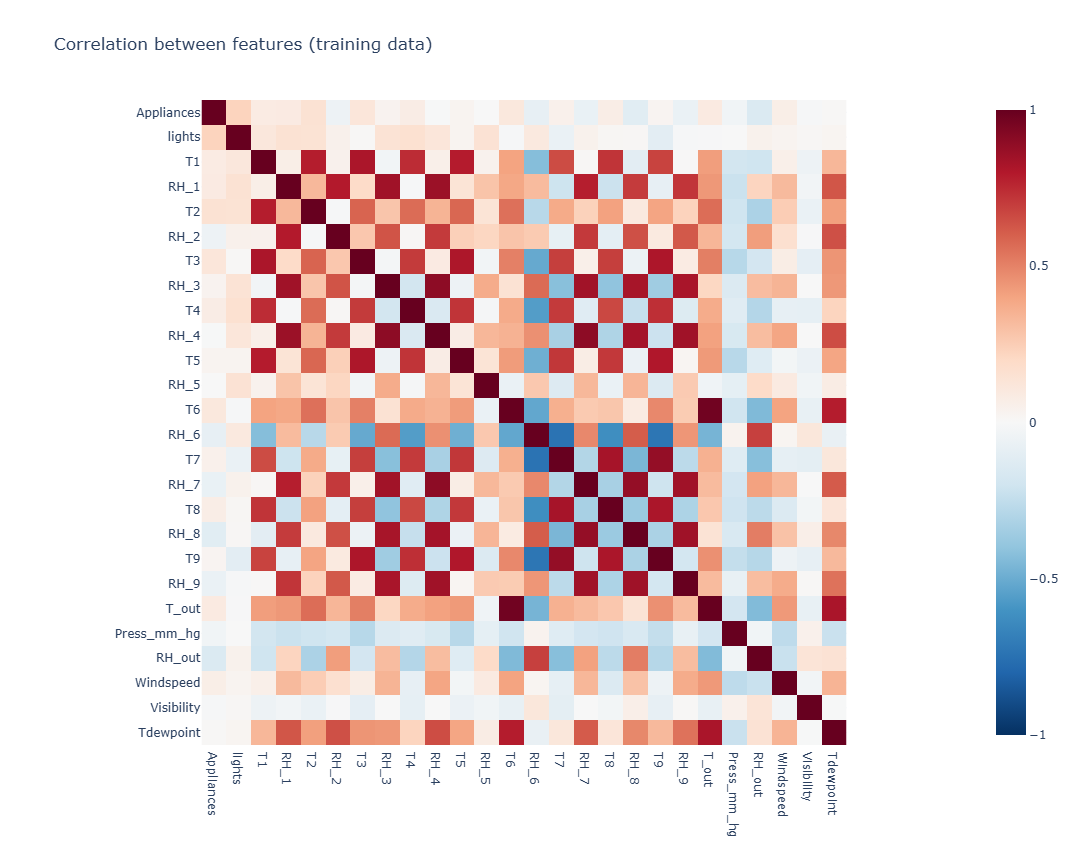

In [12]:
corr_features = train_df.drop(columns=['date', 'rv1', 'rv2']).corr()

fig = px.imshow(corr_features, color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                width=900, height=850, title='Correlation between features (training data)')
fig.show()

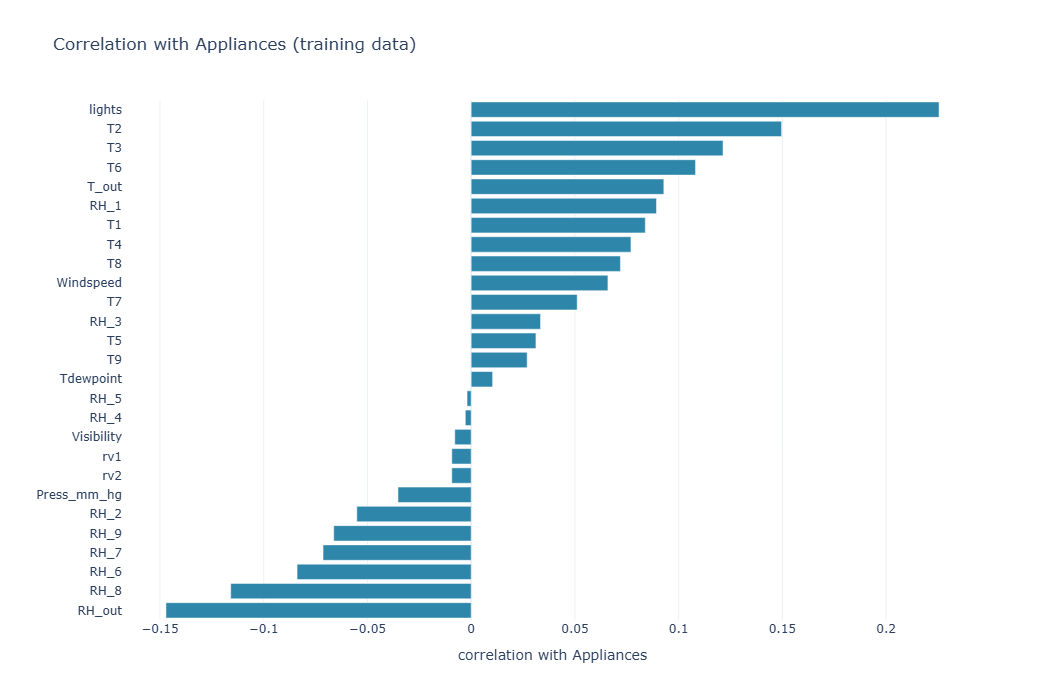

In [13]:
target_corr = train_df.drop(columns='date').corr()['Appliances'].drop('Appliances').sort_values()

fig = px.bar(x=target_corr.values, y=target_corr.index, orientation='h',
             labels={'x': 'correlation with Appliances', 'y': ''},
             height=700, title='Correlation with Appliances (training data)')
fig.show()

In [14]:
# feature pairs that are almost the same signal
upper = corr_features.where(np.triu(np.ones(corr_features.shape, dtype=bool), k=1))
pairs = upper.stack()
print(pairs[pairs.abs() > 0.9].sort_values(ascending=False).round(2))
print('T7 vs T9:', round(corr_features.loc['T7', 'T9'], 3))

# the two random columns
print(target_corr[['rv1', 'rv2']].round(3))
print('rv1 and rv2 identical:', (train_df['rv1'] == train_df['rv2']).all())

T6  T_out    0.97
dtype: float64
T7 vs T9: 0.881
rv1   -0.009
rv2   -0.009
Name: Appliances, dtype: float64
rv1 and rv2 identical: True


No single feature is strongly related to energy use. The highest correlation is with `lights` (0.23) and the strongest negative one is with `RH_out` (-0.15). Many temperature and humidity columns are strongly related to each other. `T6` and `T_out` are almost the same signal (0.97), because both measure the outside temperature, and the indoor temperatures also move together (for example `T7` and `T9`, 0.88). This matters for the linear models. `rv1` and `rv2` are identical in the training data and have a correlation of -0.009 with the target, which supports dropping them.

#### D. Patterns by time

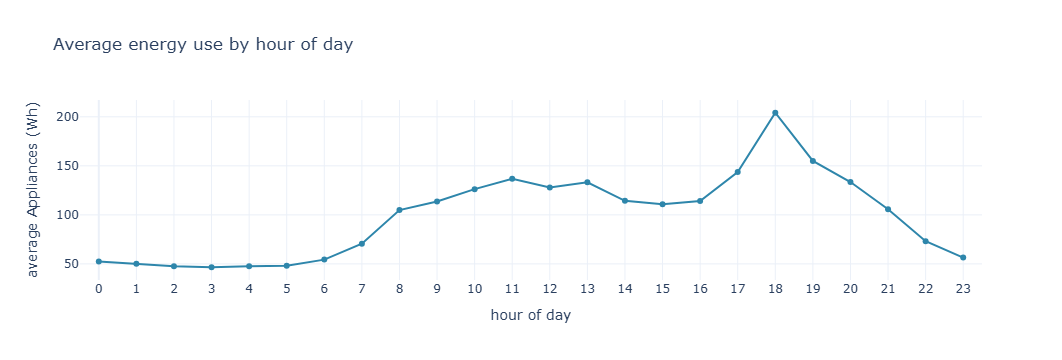

peak hour: 18 | lowest hour: 3


In [15]:
hour = train_df['date'].dt.hour.rename('hour')
day = train_df['date'].dt.dayofweek.rename('day')
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

hourly = train_df.groupby(hour)['Appliances'].mean()
fig = px.line(x=hourly.index, y=hourly.values, markers=True,
              labels={'x': 'hour of day', 'y': 'average Appliances (Wh)'},
              title='Average energy use by hour of day')
fig.update_xaxes(dtick=1, range= [-0.5, 23.5])
fig.show()

print('peak hour:', hourly.idxmax(), '| lowest hour:', hourly.idxmin())

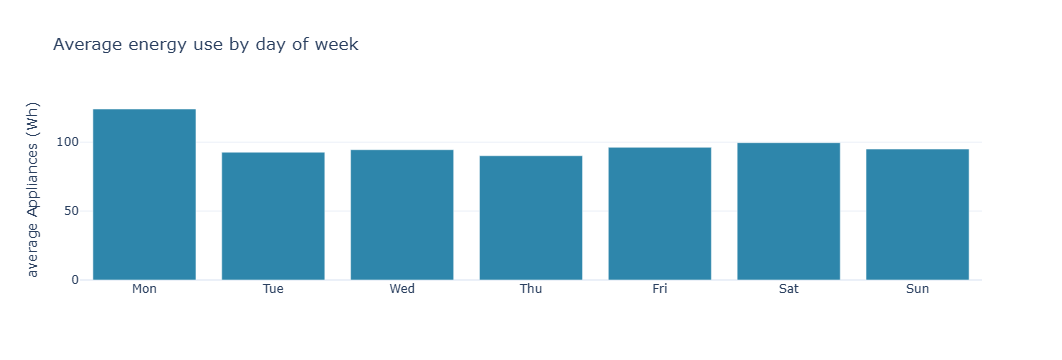

In [16]:
daily = train_df.groupby(day)['Appliances'].mean()
fig = px.bar(x=day_names, y=daily.values,
             labels={'x': '', 'y': 'average Appliances (Wh)'},
             title='Average energy use by day of week')
fig.show()

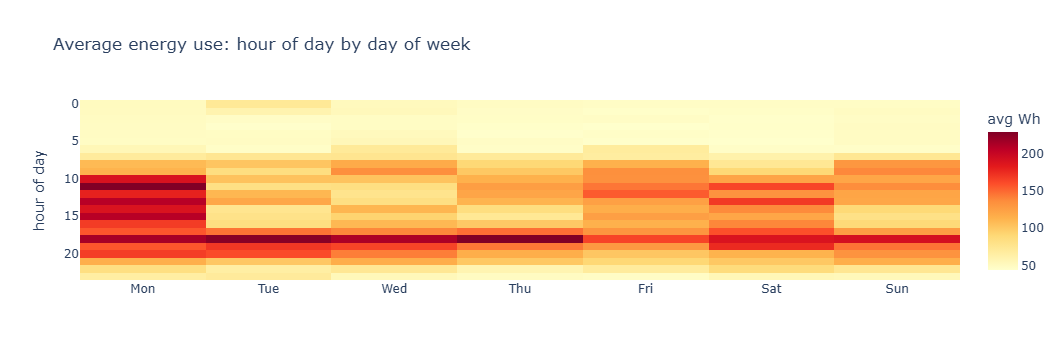

In [17]:
pivot = train_df.groupby([hour, day])['Appliances'].mean().unstack()
pivot.columns = day_names

fig = px.imshow(pivot, color_continuous_scale='YlOrRd', aspect='auto',
                labels={'color': 'avg Wh', 'y': 'hour of day'},
                title='Average energy use: hour of day by day of week')
fig.show()

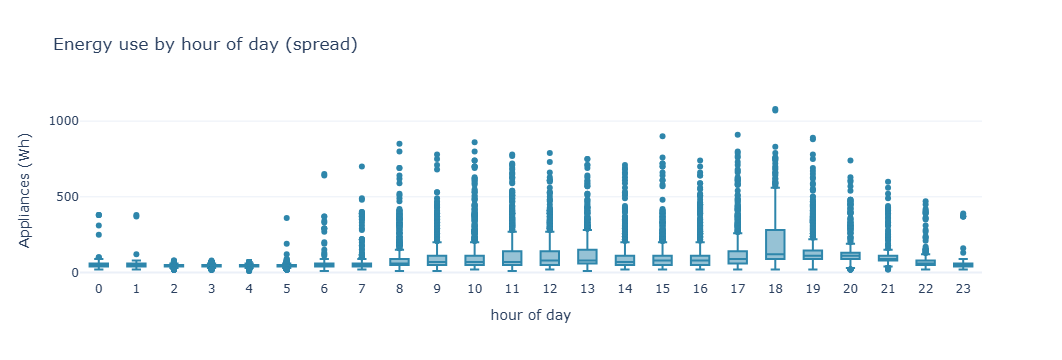

In [18]:
fig = px.box(train_df, x=hour, y='Appliances',
             labels={'Appliances': 'Appliances (Wh)'},
             title='Energy use by hour of day (spread)')
fig.update_xaxes(title='hour of day', dtick=1)
fig.show()

Energy use follows a clear daily pattern. It is lowest overnight (about 50 Wh), rises from around 7 am, stays at roughly 110 to 140 Wh during the day, and reaches its highest point at 6 pm (about 200 Wh on average). The day of the week matters much less: Tuesday to Sunday are all around 90 to 100 Wh, so weekends are not higher than weekdays. Monday is higher, mainly between about 10 am and 5 pm, which may come from a few unusual days since there are only about 14 Mondays in the training data.

The spread matters as much as the average. Overnight, readings stay close to 50 Wh, but from about 8 am they vary a lot, with many readings far above the typical value. The widest spread is at 6 pm, where the median is only about 120 Wh even though the average is near 200 Wh, because short high spikes pull the average up. These high readings show up in every daytime hour, so they look like normal household activity and not errors. Because the hour of the day matters so much, I add it as a feature.

#### E. Top features vs Appliances

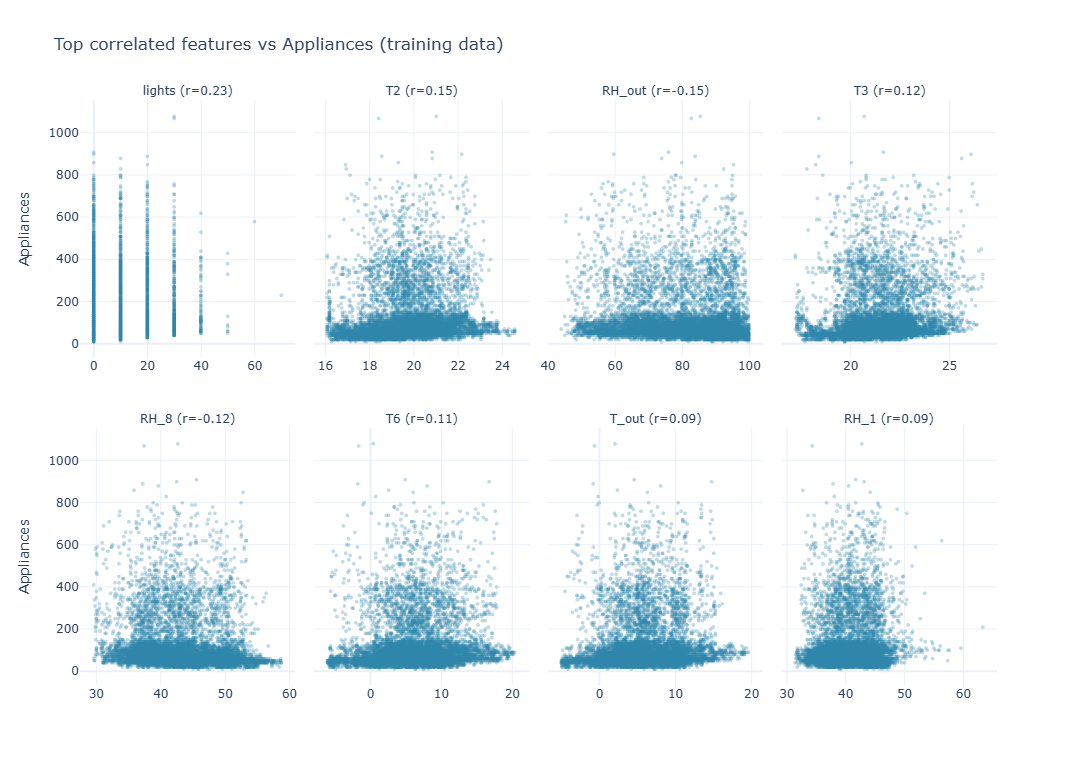

In [19]:
# the 8 features most correlated with the target (from the correlation section)
top = target_corr.drop(['rv1', 'rv2']).abs().sort_values(ascending=False).head(8).index

plot_df = train_df[top].rename(columns=lambda c: f'{c} (r={target_corr[c]:.2f})')
plot_df['Appliances'] = train_df['Appliances']

fig = px.scatter(plot_df.melt(id_vars='Appliances'), x='value', y='Appliances',
                 facet_col='variable', facet_col_wrap=4, opacity=0.3,
                 facet_row_spacing=0.12,
                 render_mode='webgl', width=1200, height=750,
                 title='Top correlated features vs Appliances (training data)')
fig.update_traces(marker_size=4)
fig.update_xaxes(matches=None, showticklabels=True, title=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=', 1)[-1]))
fig.show()

None of the top 8 features shows a clear straight-line pattern with energy use. In every plot, most readings sit in a dense band at the bottom (below about 150 Wh), and the high readings are spread across all values of the feature. The strongest link is with `lights` (r = 0.23), which is still weak. A single sensor reading does not explain energy use well, so I expect the model to need more than these raw columns, such as the hour of the day and recent energy values.

#### F. Lights on vs off

In [20]:
lights_on = train_df['lights'] > 0

print('lights on in', round(lights_on.mean() * 100, 1), '% of readings')
train_df.groupby(lights_on)['Appliances'].agg(['count', 'mean', 'median']).round(1).rename(
    index={False: 'lights off', True: 'lights on'})

lights on in 26.7 % of readings


,count,mean,median
lights,,,
lights off,10123,83.8,50.0
lights on,3691,140.0,90.0


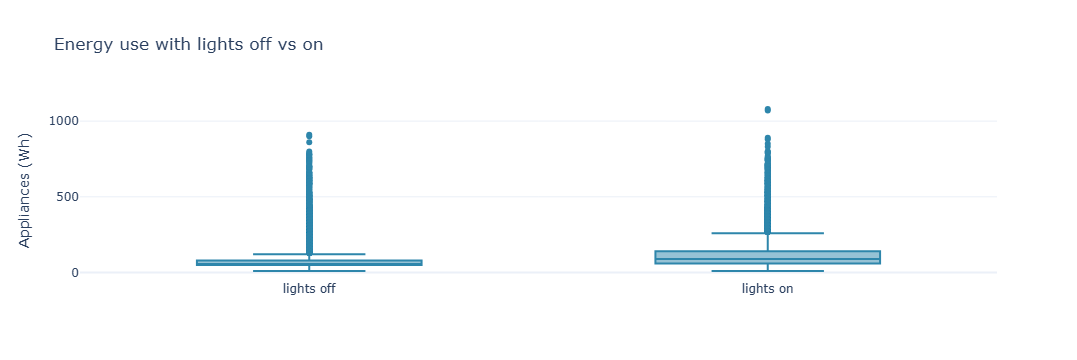

In [21]:
fig = px.box(x=lights_on.map({False: 'lights off', True: 'lights on'}),
             y=train_df['Appliances'], labels={'x': '', 'y': 'Appliances (Wh)'},
             category_orders={'x': ['lights off', 'lights on']},
             title='Energy use with lights off vs on')
fig.show()

The lights are on in about 27% of readings. When they are on, appliance energy use is clearly higher (average 140 Wh against 84 Wh, median 90 against 50). The difference is large but not a clean split, since high readings also happen with the lights off. Lights being on may simply be a sign that people are active in the house, so I treat `lights` as a useful but weak signal (r = 0.23).

## Preprocessing

#### A. Outliers

In [22]:
q1, q3 = train_df['Appliances'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
peaks = train_df['Appliances'] > upper

print('IQR upper limit:', round(upper, 1), 'Wh')
print('readings above it:', peaks.sum(), f'({peaks.mean() * 100:.1f}%)')
print('share of all energy used in those readings:',
      round(train_df.loc[peaks, 'Appliances'].sum() / train_df['Appliances'].sum() * 100, 1), '%')

IQR upper limit: 175.0 Wh
readings above it: 1609 (11.6%)
share of all energy used in those readings: 41.3 %


In [23]:
q1 = train_df.quantile(0.25, numeric_only=True)
q3 = train_df.quantile(0.75, numeric_only=True)
iqr = q3 - q1

outside = (train_df[q1.index] < q1 - 1.5 * iqr) | (train_df[q1.index] > q3 + 1.5 * iqr)
(outside.mean() * 100).round(1).drop(['Appliances', 'rv1', 'rv2']).sort_values(ascending=False)

Visibility     9.7
RH_5           7.0
lights         4.3
T4             2.0
T1             1.2
T3             0.8
Press_mm_hg    0.8
RH_7           0.5
T2             0.4
T6             0.3
Windspeed      0.3
RH_1           0.3
RH_2           0.2
RH_out         0.2
T8             0.2
T_out          0.2
RH_3           0.1
RH_8           0.1
T9             0.1
RH_4           0.0
T5             0.0
T7             0.0
RH_6           0.0
RH_9           0.0
Tdewpoint      0.0
dtype: float64

The usual outlier rule (IQR) flags readings above 175 Wh in `Appliances`, which is 1,609 readings (11.6%) in the training data. Together they account for about 41% of all the energy used. The time charts show these high readings happen regularly in the daytime and evening, so they look like real household activity and not sensor errors. I do not remove or cap them, and capping would also change the test target, so the scores would no longer measure real energy use.

For the input features, the same rule flags less than 1.5% of readings in most columns. The exceptions are `Visibility` (9.7%), `RH_5` (7.0%) and `lights` (4.3%), but their plots show that this is just the natural shape of these columns (one tall spike for `Visibility`, a long tail for `RH_5`, steps for `lights`). I leave all the features as they are.

#### B. Feature engineering

In [24]:
df['date'].diff().value_counts().head()

date
0 days 00:10:00    19734
Name: count, dtype: int64

In [25]:
# build features on the full, time-ordered data, then cut it back into the same 3 parts.
# every lag / rolling feature only looks at earlier readings, so nothing from the future gets in
full = pd.concat([train_df, val_df, test_df], ignore_index=True)

# time features
full['hour'] = full['date'].dt.hour
full['dayofweek'] = full['date'].dt.dayofweek
full['is_weekend'] = full['dayofweek'].isin([5, 6]).astype(int)
full['is_night'] = ((full['hour'] >= 22) | (full['hour'] <= 5)).astype(int)
full['is_peak_hour'] = full['hour'].between(17, 21).astype(int)

# indoor averages (T6 / RH_6 are outside the building, so they are left out)
indoor_temp = ['T1', 'T2', 'T3', 'T4', 'T5', 'T7', 'T8', 'T9']
indoor_rh = ['RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_5', 'RH_7', 'RH_8', 'RH_9']
full['avg_indoor_temp'] = full[indoor_temp].mean(axis=1)
full['avg_indoor_humidity'] = full[indoor_rh].mean(axis=1)
full['temp_range_indoor'] = full[indoor_temp].max(axis=1) - full[indoor_temp].min(axis=1)
full['temp_diff_indoor_outdoor'] = full['avg_indoor_temp'] - full['T_out']
full['humidity_diff_indoor_outdoor'] = full['avg_indoor_humidity'] - full['RH_out']

# lag features: energy use 10 min, 20 min, 30 min, 1 h, 2 h, 1 day and 2 days ago
for lag in [1, 2, 3, 6, 12, 144, 288]:
    full[f'lag_{lag}'] = full['Appliances'].shift(lag)

# rolling features over earlier readings (shifted by 1, so the current value is not included)
past = full['Appliances'].shift(1)
for window in [3, 6, 12, 24]:
    full[f'rolling_mean_{window}'] = past.rolling(window).mean()
full['rolling_std_6'] = past.rolling(6).std()
full['rolling_max_6'] = past.rolling(6).max()
full['rolling_min_6'] = past.rolling(6).min()

# cut back into train / validation / test; only the first rows of train have empty lags
n_train, n_val = len(train_df), len(val_df)
train_fe = full.iloc[:n_train].dropna().reset_index(drop=True)
val_fe = full.iloc[n_train:n_train + n_val].reset_index(drop=True)
test_fe = full.iloc[n_train + n_val:].reset_index(drop=True)

print(train_fe.shape, val_fe.shape, test_fe.shape)
print('empty values in val / test:', val_fe.isnull().sum().sum(), test_fe.isnull().sum().sum())

(13526, 53) (2960, 53) (2961, 53)
empty values in val / test: 0 0


Every reading is exactly 10 minutes after the previous one, so `lag_144` is one day back and `lag_288` is two days back.

#### C. Model inputs and scaling

In [26]:
# inputs: everything except the date, the two random columns and the target itself
drop_cols = ['date', 'rv1', 'rv2', 'Appliances']
feature_names = [c for c in train_fe.columns if c not in drop_cols]

y_train = train_fe['Appliances']
y_val = val_fe['Appliances']
y_test = test_fe['Appliances']

# the scaler learns its median and spread from the training data only
scaler = RobustScaler()
X_train = pd.DataFrame(scaler.fit_transform(train_fe[feature_names]), columns=feature_names)
X_val = pd.DataFrame(scaler.transform(val_fe[feature_names]), columns=feature_names)
X_test = pd.DataFrame(scaler.transform(test_fe[feature_names]), columns=feature_names)

print(X_train.shape, X_val.shape, X_test.shape)

(13526, 49) (2960, 49) (2961, 49)


The model inputs are all columns except `date`, `rv1`, `rv2` and the target `Appliances` itself, which leaves 49 features. I scale them with `RobustScaler`, which uses the median and the middle 50% of values, so the large spikes in energy use (and in the lag features built from it) don't squash the rest. The scaler learns from the training data only and is then applied to validation and test. Scaling matters for the linear models, SVR and KNN, and makes no difference to the tree models.

## Model Building & Comparison

All models are trained on the training set and compared on the validation set. The test set stays untouched until the final evaluation.

As a reference point I first check the simplest possible forecast: predict that the next reading equals the last one (`lag_1`). A model is only useful if it clearly beats this.

In [27]:
def calculate_metrics(y_true, y_pred, prefix=''):
    mse = mean_squared_error(y_true, y_pred)
    return {f'{prefix}R2': r2_score(y_true, y_pred),
            f'{prefix}MSE': mse,
            f'{prefix}RMSE': np.sqrt(mse),
            f'{prefix}MAE': mean_absolute_error(y_true, y_pred)}

# simplest forecast: the next reading is the same as the last one
baseline = calculate_metrics(y_val, val_fe['lag_1'], 'Val_')
print({name: round(float(value), 3) for name, value in baseline.items()})

{'Val_R2': 0.481, 'Val_MSE': 4412.905, 'Val_RMSE': 66.43, 'Val_MAE': 26.162}


In [28]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1),
}

rows = []
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    train_scores = calculate_metrics(y_train, model.predict(X_train), 'Train_')
    val_scores = calculate_metrics(y_val, model.predict(X_val), 'Val_')
    rows.append({'Model': name, **train_scores, **val_scores})
    trained_models[name] = model

results_df = pd.DataFrame(rows).sort_values('Val_RMSE').reset_index(drop=True)
results_df['R2_gap'] = results_df['Train_R2'] - results_df['Val_R2']
best_model_name = results_df.loc[0, 'Model']

results_df[['Model', 'Train_R2', 'Val_R2', 'R2_gap', 'Train_RMSE',
            'Val_RMSE', 'Val_MSE', 'Val_MAE']].round(3)

,Model,Train_R2,Val_R2,R2_gap,Train_RMSE,Val_RMSE,Val_MSE,Val_MAE
0,Lasso,0.602,0.582,0.020,67.522,59.658,3559.117,26.186
1,Ridge,0.609,0.580,0.029,66.949,59.779,3573.501,28.178
2,Linear Regression,0.609,0.580,0.029,66.949,59.788,3574.599,28.202
3,XGBoost,0.951,0.250,0.701,23.687,79.865,6378.396,45.074
4,Random Forest,0.947,0.093,0.854,24.668,87.829,7714.005,46.001
5,Gradient Boosting,0.701,0.063,0.638,58.506,89.288,7972.283,45.847


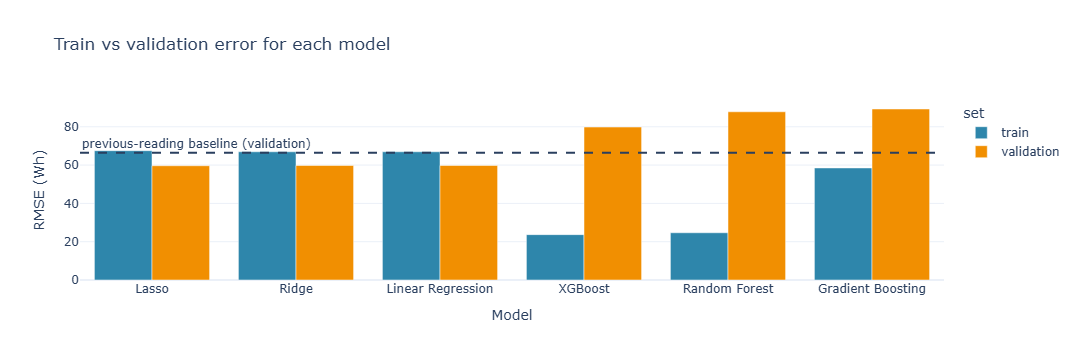

In [29]:
plot_df = results_df.rename(columns={'Train_RMSE': 'train', 'Val_RMSE': 'validation'}).melt(
    id_vars='Model', value_vars=['train', 'validation'], var_name='set', value_name='RMSE (Wh)')

fig = px.bar(plot_df, x='Model', y='RMSE (Wh)', color='set', barmode='group',
             color_discrete_sequence=['#2E86AB', '#F18F01'],
             title='Train vs validation error for each model')
fig.add_hline(y=baseline['Val_RMSE'], line_dash='dash',
              annotation_text='previous-reading baseline (validation)',
              annotation_position='top left')
fig.show()

The simplest forecast, copying the previous reading, gives a validation RMSE of 66.4 Wh (R² 0.48). Lasso has the lowest validation RMSE (59.7 Wh, R² 0.58), with Ridge and Linear Regression almost identical, so I take Lasso as the best model. It beats the baseline on RMSE and R², but its average miss (MAE, 26.2 Wh) is the same as the baseline's, so it mainly helps with the larger errors and is no better on typical readings. The three tree-based models fit the training data very closely (R² 0.70 to 0.95) but are worse than the baseline on new data (validation RMSE 80 to 89 Wh), so with default settings they do not carry over to new data.

## LSTM: predicting energy use from the last 2 hours of readings

In [30]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(RANDOM_STATE)

steps = 12   # each window is 12 rows = 2 hours, ending with the row being predicted

# stack the three parts in time order so the first windows of val and test can look back
X_all = np.vstack([X_train.values, X_val.values, X_test.values])
y_all = np.concatenate([y_train.values, y_val.values, y_test.values])

windows = np.array([X_all[i - steps + 1:i + 1] for i in range(steps - 1, len(X_all))])
targets = y_all[steps - 1:]

n_tr = len(X_train) - steps + 1
X_tr_seq, y_tr_seq = windows[:n_tr], targets[:n_tr]
X_vl_seq, y_vl_seq = windows[n_tr:n_tr + len(X_val)], targets[n_tr:n_tr + len(X_val)]

print(X_tr_seq.shape, X_vl_seq.shape)
print('same validation rows as the other models:', (y_vl_seq == y_val.values).all())

(13515, 12, 49) (2960, 12, 49)
same validation rows as the other models: True


In [31]:
lstm_model = Sequential([
    Input(shape=(steps, X_all.shape[1])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1),
])
lstm_model.compile(optimizer='adam', loss='mse')

history = lstm_model.fit(X_tr_seq, y_tr_seq, validation_split=0.15, epochs=50, batch_size=64,
                         callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
                         verbose=0)
print('epochs run:', len(history.history['loss']), 'of a maximum of 50 | best epoch:',
      int(np.argmin(history.history['val_loss'])) + 1)

epochs run: 25 of a maximum of 50 | best epoch: 15


In [32]:
lstm_train_pred = lstm_model.predict(X_tr_seq, verbose=0).ravel()
lstm_val_pred = lstm_model.predict(X_vl_seq, verbose=0).ravel()

lstm_scores = {**calculate_metrics(y_tr_seq, lstm_train_pred, 'Train_'),
               **calculate_metrics(y_vl_seq, lstm_val_pred, 'Val_')}
print({name: round(float(value), 3) for name, value in lstm_scores.items()})

{'Train_R2': 0.669, 'Train_MSE': 3795.682, 'Train_RMSE': 61.609, 'Train_MAE': 28.852, 'Val_R2': 0.554, 'Val_MSE': 3795.175, 'Val_RMSE': 61.605, 'Val_MAE': 29.913}


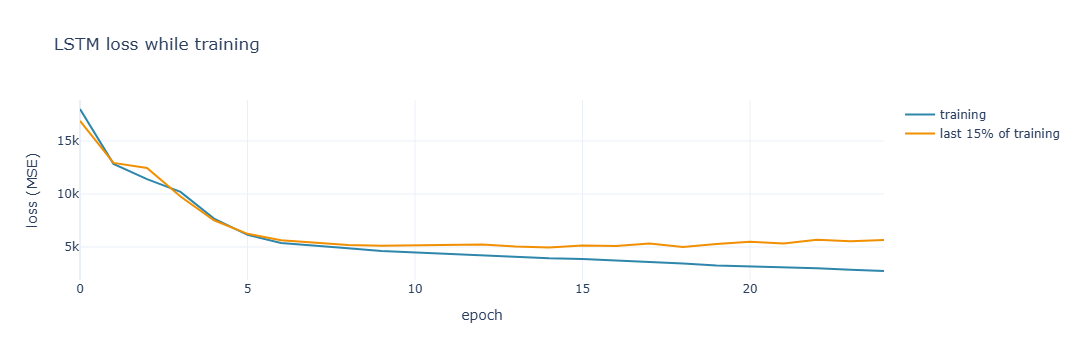

In [33]:
loss = pd.DataFrame(history.history).rename(columns={'loss': 'training', 'val_loss': 'last 15% of training'})
fig = px.line(loss, labels={'index': 'epoch', 'value': 'loss (MSE)', 'variable': ''},
              color_discrete_sequence=['#2E86AB', '#F18F01'], title='LSTM loss while training')
fig.show()

The LSTM was trained on 13,515 windows of 12 rows (2 hours, 49 inputs per row) and scored on 2,960 validation windows, which are exactly the validation rows the other models are scored on. Training ran for 25 of a maximum of 50 epochs. The loss on the last 15% of the training data was lowest at epoch 15 and then stopped improving while the training loss kept falling, so I keep the weights from epoch 15. On the validation set it reaches an RMSE of 61.6 Wh and an R² of 0.55. That is better than copying the previous reading (66.4 Wh, 0.48) but not as good as Lasso (59.7 Wh, 0.58), and its average miss (MAE, 29.9 Wh) is worse than both. Training and validation errors are about equal (RMSE 61.6 for both), so there is no large gap between them. LSTM scores can change slightly between runs or machines.

## ARIMA: predicting energy use from its own past readings

ARIMA predicts each reading from the readings just before it and the errors of its recent guesses. It uses only the energy series itself, not the weather, the hour or the lights. Like the other models, it predicts each validation reading one step ahead, using the real earlier readings.

In [34]:
from statsmodels.tsa.stattools import adfuller

print('p-value:', round(adfuller(y_train.values)[1], 4))

p-value: 0.0


In [35]:
from statsmodels.tsa.arima.model import ARIMA

# try a few small orders and keep the one with the lowest AIC on the training data
aic = {}
for p in [1, 2, 3, 4, 5]:
    for q in [0, 1]:
        aic[(p, 0, q)] = ARIMA(y_train.values, order=(p, 0, q)).fit().aic

best_order = min(aic, key=aic.get)
print({order: round(value) for order, value in aic.items()})
print('chosen order:', best_order)

C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting par

{(1, 0, 0): 153184, (1, 0, 1): 153095, (2, 0, 0): 153123, (2, 0, 1): 153040, (3, 0, 0): 152896, (3, 0, 1): 152644, (4, 0, 0): 152834, (4, 0, 1): 152636, (5, 0, 0): 152798, (5, 0, 1): 152637}
chosen order: (4, 0, 1)


In [36]:
arima_fit = ARIMA(y_train.values, order=best_order).fit()

# same coefficients, now run over train + validation, so each validation reading is
# predicted one step ahead from the real readings before it
full_series = np.concatenate([y_train.values, y_val.values])
arima_run = arima_fit.apply(full_series)
arima_val_pred = arima_run.predict(start=len(y_train), end=len(full_series) - 1)

arima_scores = {**calculate_metrics(y_train, arima_fit.fittedvalues, 'Train_'),
                **calculate_metrics(y_val, arima_val_pred, 'Val_')}
print(len(arima_val_pred), 'validation predictions')
print({name: round(float(value), 3) for name, value in arima_scores.items()})

C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


2960 validation predictions
{'Train_R2': 0.594, 'Train_MSE': 4654.797, 'Train_RMSE': 68.226, 'Train_MAE': 31.142, 'Val_R2': 0.575, 'Val_MSE': 3616.292, 'Val_RMSE': 60.136, 'Val_MAE': 26.339}


The training series is steady (ADF test p-value close to 0), so no differencing is needed (d = 0). Among the orders I tried (p = 1 to 5, q = 0 to 1), ARIMA(4, 0, 1) has the lowest AIC on the training data, and the AIC stops improving after p = 4 (152,636 for p = 4 against 152,637 for p = 5). On the 2,960 validation rows, predicted one step ahead from the real earlier readings, it reaches an RMSE of 60.1 Wh, an MAE of 26.3 Wh and an R² of 0.575. That beats copying the previous reading on RMSE and R² (66.4 Wh, 0.48), while the average miss (MAE) is about the same (26.2 Wh). It is also better than the LSTM (61.6 Wh) and almost as good as Lasso (59.7 Wh, 0.58), even though ARIMA sees only past energy readings and not the weather, the hour or the lights.

## All models compared

Every model is scored on the same 2,960 validation rows. The best model is the one with the lowest validation RMSE.

In [37]:
# add ARIMA and the LSTM to the results table, then pick the winner by validation RMSE
extra = pd.DataFrame([{'Model': f'ARIMA{best_order}', **arima_scores},
                      {'Model': 'LSTM', **lstm_scores}])

results_df = pd.concat([results_df[~results_df['Model'].isin(extra['Model'])].drop(columns='R2_gap'), extra],
                       ignore_index=True)
results_df = results_df.sort_values('Val_RMSE').reset_index(drop=True)
results_df['R2_gap'] = results_df['Train_R2'] - results_df['Val_R2']
best_model_name = results_df.loc[0, 'Model']
print('best model:', best_model_name)

# the baseline goes in the table for comparison only, after the winner is picked
baseline_row = pd.DataFrame([{'Model': 'Previous reading (baseline)', **baseline}])
table = pd.concat([results_df, baseline_row], ignore_index=True).sort_values('Val_RMSE').reset_index(drop=True)

table[['Model', 'Val_RMSE', 'Val_MAE', 'Val_MSE', 'Val_R2', 'Train_RMSE', 'Train_R2']].round(3)

best model: Lasso


,Model,Val_RMSE,Val_MAE,Val_MSE,Val_R2,Train_RMSE,Train_R2
0,Lasso,59.658,26.186,3559.117,0.582,67.522,0.602
1,Ridge,59.779,28.178,3573.501,0.580,66.949,0.609
2,Linear Regression,59.788,28.202,3574.599,0.580,66.949,0.609
3,"ARIMA(4, 0, 1)",60.136,26.339,3616.292,0.575,68.226,0.594
4,LSTM,61.605,29.913,3795.175,0.554,61.609,0.669
5,Previous reading (baseline),66.430,26.162,4412.905,0.481,NaN,NaN
6,XGBoost,79.865,45.074,6378.396,0.250,23.687,0.951
7,Random Forest,87.829,46.001,7714.005,0.093,24.668,0.947
8,Gradient Boosting,89.288,45.847,7972.283,0.063,58.506,0.701


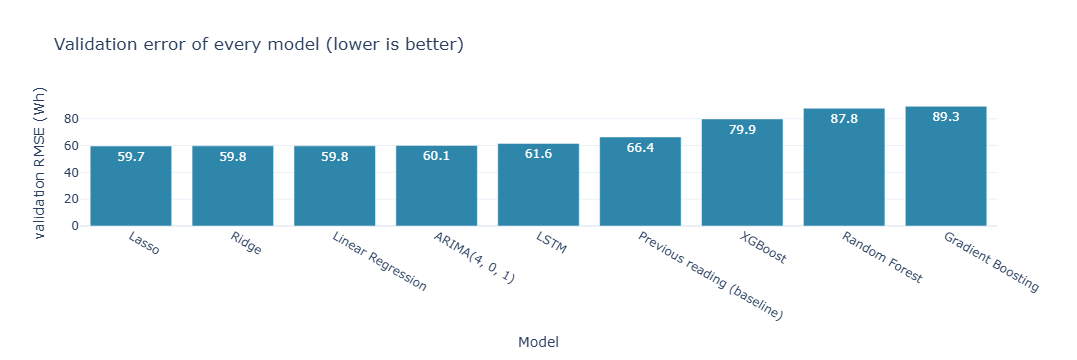

In [38]:
fig = px.bar(table, x='Model', y='Val_RMSE', text_auto='.1f',
             labels={'Val_RMSE': 'validation RMSE (Wh)'},
             title='Validation error of every model (lower is better)')
fig.show()

On the same 2,960 validation rows, Lasso has the lowest RMSE (59.7 Wh, R² 0.58), followed closely by Ridge and Linear Regression (59.8 Wh), ARIMA (60.1 Wh) and the LSTM (61.6 Wh). Copying the previous reading gives 66.4 Wh, so these five all beat it on RMSE, while the three tree-based models (80 to 89 Wh) do not. The gap between Lasso and ARIMA is under 1 Wh on about 20 days of data, so the ranking of the top models could change on another period. I check this with backtesting later. I take Lasso forward to tuning because it has the lowest validation RMSE and, unlike ARIMA, it can show which inputs matter.

## Tuning Lasso: choosing the best alpha

Lasso is the best model so far, so I tune it. Its main setting is `alpha`, which controls how strongly it shrinks the weights of weak inputs. I try 9 values and score each with 5 time-ordered folds on the training data (each fold trains on earlier rows and is checked on the next block), so the validation set plays no part in the choice.

In [39]:
from sklearn.model_selection import GridSearchCV

# the winner is Lasso, so that is the model I tune
best_model = trained_models[best_model_name]

search = GridSearchCV(Lasso(max_iter=10000),
                      param_grid={'alpha': np.logspace(-3, 1, 9)},
                      cv=TimeSeriesSplit(n_splits=5),
                      scoring='neg_root_mean_squared_error')
search.fit(X_train, y_train)

tuned_model = search.best_estimator_
best_params = search.best_params_
print('best alpha:', round(best_params['alpha'], 4))

best alpha: 0.3162


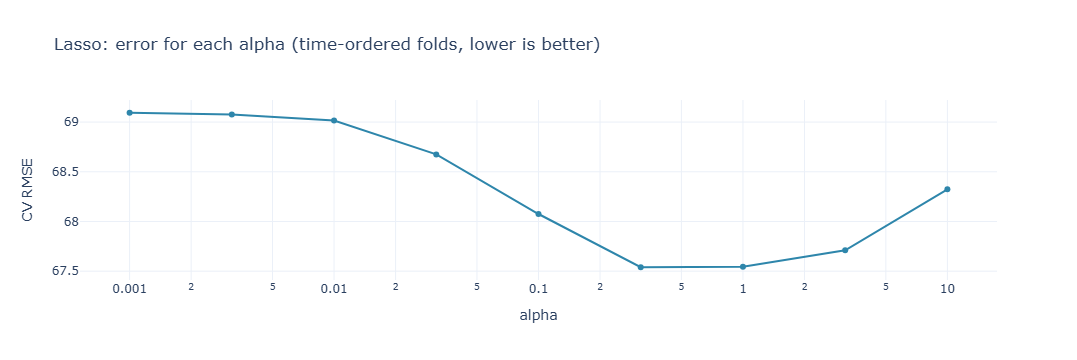

In [40]:
alpha_scores = pd.DataFrame({'alpha': np.array(search.cv_results_['param_alpha'], dtype=float),
                             'CV RMSE': -search.cv_results_['mean_test_score']})
fig = px.line(alpha_scores, x='alpha', y='CV RMSE', markers=True, log_x=True,
              title='Lasso: error for each alpha (time-ordered folds, lower is better)')
fig.show()

In [41]:
compare = {'default (alpha 1.0)': best_model, 'tuned': tuned_model}
before_after = pd.DataFrame({
    name: {**calculate_metrics(y_train, m.predict(X_train), 'Train_'),
           **calculate_metrics(y_val, m.predict(X_val), 'Val_')}
    for name, m in compare.items()}).T
before_after[['Train_RMSE', 'Val_RMSE', 'Val_MAE', 'Val_MSE', 'Val_R2']].round(3)

,Train_RMSE,Val_RMSE,Val_MAE,Val_MSE,Val_R2
default (alpha 1.0),67.522,59.658,26.186,3559.117,0.582
tuned,67.209,59.400,26.704,3528.338,0.585


The error is highest for very small alphas, where Lasso keeps almost all 49 inputs, lowest between 0.3 and 1, and rises again at 10, where it removes useful inputs. The search picks alpha = 0.316, but the default of 1.0 is almost as good in the folds, so alpha matters little here. On the validation set the tuned model reaches an RMSE of 59.4 Wh and an R² of 0.585, against 59.7 Wh and 0.582 for the default. That is a small gain, and the average miss (MAE) is slightly worse (26.7 against 26.2 Wh). The error in the chart is higher than the validation error because the folds use earlier, smaller parts of the training data, so I only use it to compare alphas. I keep the tuned model.

## Backtesting: Lasso, ARIMA and the previous reading over 8 weeks

One validation period of about 20 days can be lucky or unlucky, so I repeat the test on 8 different weeks. The first model is trained on the first half of the train + validation data. Then each of the next 8 weeks is predicted in turn, retraining on everything before that week each time. The test set is not used here.

In [42]:
from sklearn.base import clone

X_bt = pd.concat([X_train, X_val], ignore_index=True)
y_bt = pd.concat([y_train, y_val], ignore_index=True)
prev_bt = pd.concat([train_fe['lag_1'], val_fe['lag_1']], ignore_index=True)  # previous reading, unscaled

week = 1008                      # 7 days of 10-minute readings
first_train = len(X_bt) // 2     # the first model trains on the first half

rows = []
for k in range(8):
    train_end = first_train + k * week
    test_end = train_end + week
    y_week = y_bt[train_end:test_end]

    lasso_pred = clone(tuned_model).fit(X_bt[:train_end], y_bt[:train_end]).predict(X_bt[train_end:test_end])

    # ARIMA: refit on the earlier rows, then predict each reading of the week one step ahead
    arima_run = ARIMA(y_bt[:train_end].values, order=best_order).fit().apply(y_bt[:test_end].values)
    arima_pred = arima_run.predict(start=train_end, end=test_end - 1)

    predictions = {'Lasso (tuned)': lasso_pred, 'ARIMA': arima_pred,
                   'previous reading': prev_bt[train_end:test_end]}
    for name, pred in predictions.items():
        rows.append({'window': k + 1, 'model': name,
                     'RMSE': np.sqrt(mean_squared_error(y_week, pred)),
                     'MAE': mean_absolute_error(y_week, pred),
                     'R2': r2_score(y_week, pred)})

backtest = pd.DataFrame(rows)

C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Sai Kalyan\anaconda3\envs\energy_consumption_env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting par

In [43]:
wide = backtest.pivot(index='window', columns='model', values='RMSE')
print('Lasso beats ARIMA in', (wide['Lasso (tuned)'] < wide['ARIMA']).sum(), 'of', len(wide), 'weeks')
print('Lasso beats the previous reading in', (wide['Lasso (tuned)'] < wide['previous reading']).sum(), 'of', len(wide), 'weeks')

backtest.groupby('model')[['RMSE', 'MAE', 'R2']].agg(['mean', 'std']).round(2)

Lasso beats ARIMA in 7 of 8 weeks
Lasso beats the previous reading in 8 of 8 weeks


RMSE          MAE          R2      
                   mean   std   mean   std  mean   std
model                                                 
ARIMA             63.73  7.29  28.10  3.94  0.58  0.04
Lasso (tuned)     63.19  7.35  28.13  3.90  0.59  0.03
previous reading  70.01  8.08  28.37  4.33  0.49  0.05

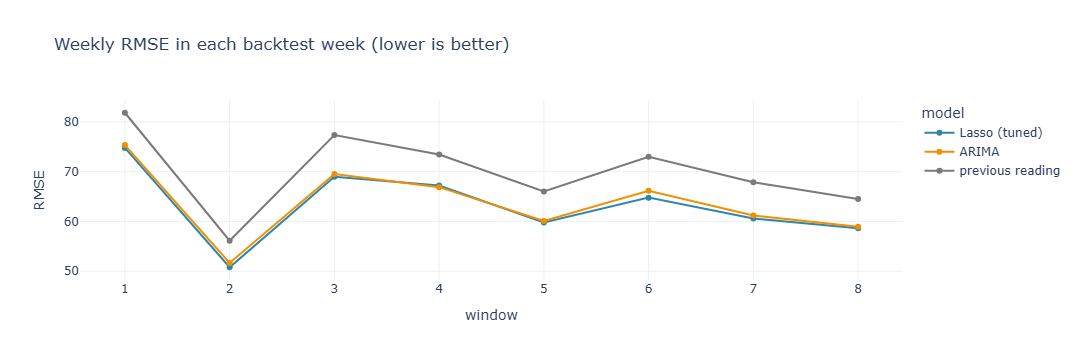

In [44]:
fig = px.line(backtest, x='window', y='RMSE', color='model', markers=True,
              color_discrete_sequence=['#2E86AB', '#F18F01', '#7A7A7A'],
              title='Weekly RMSE in each backtest week (lower is better)')
fig.update_xaxes(dtick=1)
fig.show()

I repeated the test on 8 different weeks, retraining each time on all earlier data (the test set is not used). Lasso beats copying the previous reading in all 8 weeks (mean RMSE 63.2 Wh against 70.0 Wh, R² 0.59 against 0.49). It beats ARIMA in 7 of 8 weeks, but only by a small margin (63.2 against 63.7 Wh), so the two are close. I keep Lasso because it is ahead on average and in most weeks and, unlike ARIMA, it can show which inputs matter. The average miss (MAE) is about the same for all three models (28.1 to 28.4 Wh), so their advantage is in avoiding the larger misses. Weekly RMSE ranges from about 51 to 75 Wh for Lasso, and all three models rise and fall together, so some weeks are simply harder than others and a single short test period can be misleading. This is also why the single validation score (59.4 Wh) looks better than the weekly average. The first five weeks lie in the training period, which was used to choose alpha and the ARIMA order, so they are slightly flattering to both models.

## Feature importance

I check which inputs the tuned Lasso relies on, using the validation set (not the test set). Permutation importance shuffles one input and measures how much the validation error (RMSE) goes up: the bigger the increase, the more the model relied on it. Many inputs carry almost the same information (for example the lag and rolling features), so I also shuffle whole groups of inputs together.

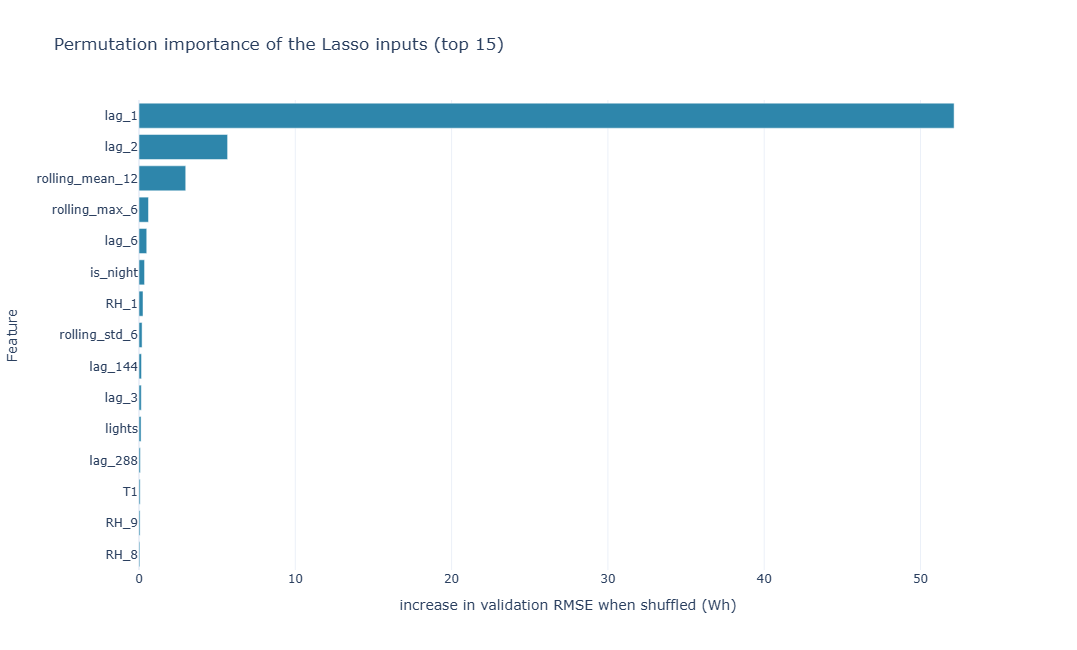

In [45]:
perm = permutation_importance(tuned_model, X_val, y_val, n_repeats=10,
                              scoring='neg_root_mean_squared_error',
                              random_state=RANDOM_STATE, n_jobs=-1)

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': perm.importances_mean}
                             ).sort_values('Importance', ascending=False).reset_index(drop=True)

fig = px.bar(importance_df.head(15).iloc[::-1], x='Importance', y='Feature', orientation='h',
             labels={'Importance': 'increase in validation RMSE when shuffled (Wh)'},
             title='Permutation importance of the Lasso inputs (top 15)')
fig.update_layout(height=650)
fig.update_yaxes(dtick=1)
fig.show()

inputs Lasso keeps: 26 of 49


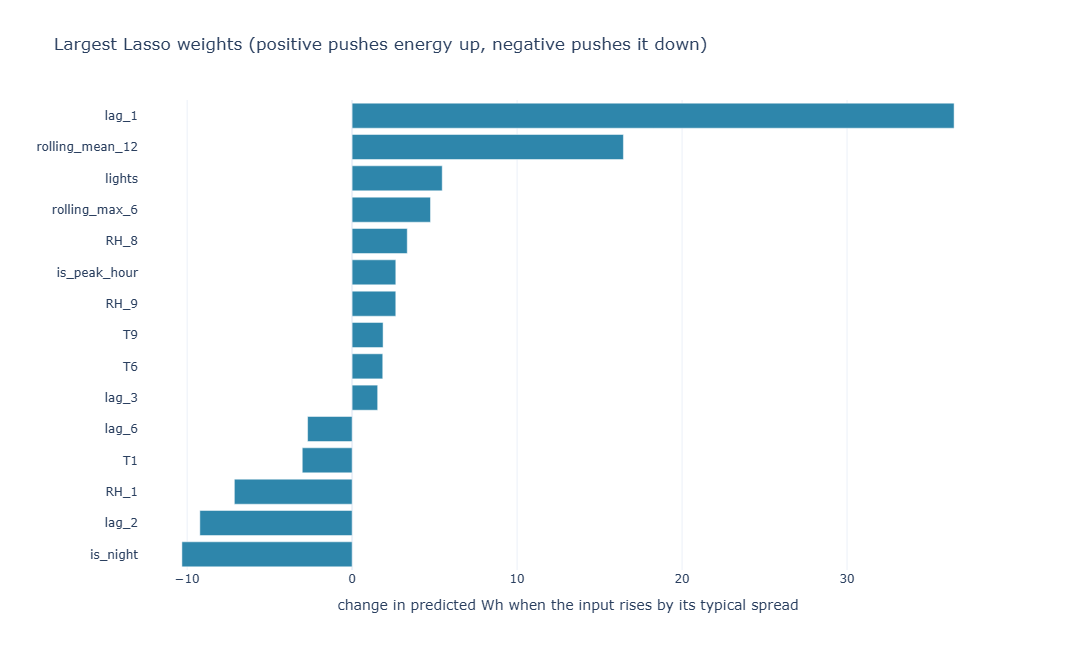

In [46]:
coefs = pd.Series(tuned_model.coef_, index=feature_names)
print('inputs Lasso keeps:', (coefs != 0).sum(), 'of', len(coefs))

top_coefs = coefs[coefs.abs().sort_values(ascending=False).index[:15]].sort_values()
fig = px.bar(x=top_coefs.values, y=top_coefs.index, orientation='h',
             labels={'x': 'change in predicted Wh when the input rises by its typical spread', 'y': ''},
             title='Largest Lasso weights (positive pushes energy up, negative pushes it down)')
fig.update_layout(height=650)
fig.update_yaxes(dtick=1)
fig.show()

inputs covered: 49 of 49


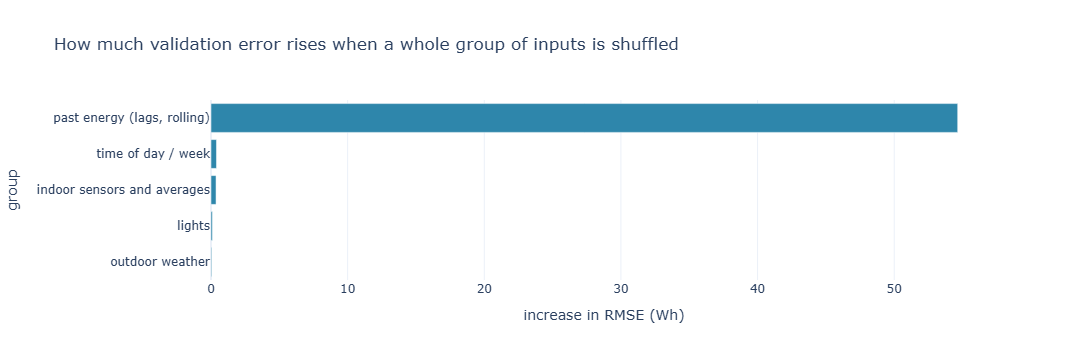

In [47]:
groups = {
    'past energy (lags, rolling)': [c for c in feature_names if c.startswith(('lag_', 'rolling_'))],
    'time of day / week': ['hour', 'dayofweek', 'is_weekend', 'is_night', 'is_peak_hour'],
    'lights': ['lights'],
    'indoor sensors and averages': indoor_temp + indoor_rh + ['avg_indoor_temp', 'avg_indoor_humidity',
                                   'temp_range_indoor', 'temp_diff_indoor_outdoor',
                                   'humidity_diff_indoor_outdoor'],
    'outdoor weather': ['T6', 'RH_6', 'T_out', 'RH_out', 'Press_mm_hg', 'Windspeed',
                        'Visibility', 'Tdewpoint'],
}
print('inputs covered:', sum(len(v) for v in groups.values()), 'of', len(feature_names))

rng = np.random.default_rng(RANDOM_STATE)
base_rmse = np.sqrt(mean_squared_error(y_val, tuned_model.predict(X_val)))

rows = []
for name, cols in groups.items():
    increases = []
    for _ in range(10):
        shuffled = X_val.copy()
        # one shuffle for the whole group, so its columns stay consistent with each other
        shuffled[cols] = X_val[cols].values[rng.permutation(len(X_val))]
        increases.append(np.sqrt(mean_squared_error(y_val, tuned_model.predict(shuffled))) - base_rmse)
    rows.append({'group': name, 'increase in RMSE (Wh)': np.mean(increases)})

group_importance = pd.DataFrame(rows).sort_values('increase in RMSE (Wh)')
fig = px.bar(group_importance, x='increase in RMSE (Wh)', y='group', orientation='h',
             title='How much validation error rises when a whole group of inputs is shuffled')
fig.show()

In [48]:
group_importance.round(2)

,group,increase in RMSE (Wh)
4,outdoor weather,0.05
2,lights,0.10
3,indoor sensors and averages,0.37
1,time of day / week,0.40
0,"past energy (lags, rolling)",54.65


The tuned Lasso relies almost entirely on past energy readings. Shuffling the past-energy inputs (lags and rolling averages) raises the validation RMSE by 54.7 Wh, from about 59 to about 114 Wh, so the error nearly doubles. Shuffling any other group changes it by less than half a Wh: time of day and week 0.40, indoor sensors 0.37, lights 0.10 and outdoor weather 0.05. On its own, `lag_1` accounts for about 52 Wh of the increase. Lasso keeps 26 of the 49 inputs; its largest weight is on `lag_1` and its largest negative weight is on `is_night`. This does not mean that time of day or weather have no effect on energy use: the recent readings already carry that information, so these inputs add little once the lags are there. Inputs that are almost copies of each other can share weight, so single weights should not be read too literally.

## What can the model do without recent energy readings?

The importance results show that the model relies on past energy readings. To see how much, I train Lasso (with the tuned alpha) on three sets of inputs and score each on the validation set; the test set is not used. The previous reading is also hidden inside the rolling features, because their windows end at the previous reading, so I remove `lag_1` and all rolling features together. The last set removes every past-energy input and keeps only the weather, the time of day and the lights.

In [49]:
past = [c for c in feature_names if c.startswith(('lag_', 'rolling_'))]
# everything that contains the previous reading: lag_1 and every rolling feature
recent = ['lag_1'] + [c for c in feature_names if c.startswith('rolling_')]

scenarios = {
    'all inputs': feature_names,
    'without the previous reading (lag_1 and rolling)': [c for c in feature_names if c not in recent],
    'without any past energy (lags and rolling)': [c for c in feature_names if c not in past],
}

rows = []
for name, cols in scenarios.items():
    model = Lasso(alpha=best_params['alpha'], max_iter=10000).fit(X_train[cols], y_train)
    scores = calculate_metrics(y_val, model.predict(X_val[cols]), 'Val_')
    rows.append({'inputs': name, 'number of inputs': len(cols), **scores})

# floor: always predict the training average
mean_scores = calculate_metrics(y_val, np.full(len(y_val), y_train.mean()), 'Val_')
rows.append({'inputs': 'always predict the training average', 'number of inputs': 0, **mean_scores})

lag_test = pd.DataFrame(rows)
lag_test[['inputs', 'number of inputs', 'Val_RMSE', 'Val_MAE', 'Val_R2']].round(2)

,inputs,number of inputs,Val_RMSE,Val_MAE,Val_R2
0,all inputs,49,59.40,26.70,0.59
1,without the previous reading (lag_1 and rolling),41,77.98,38.71,0.29
2,without any past energy (lags and rolling),35,89.34,58.40,0.06
3,always predict the training average,0,92.41,54.09,-0.00


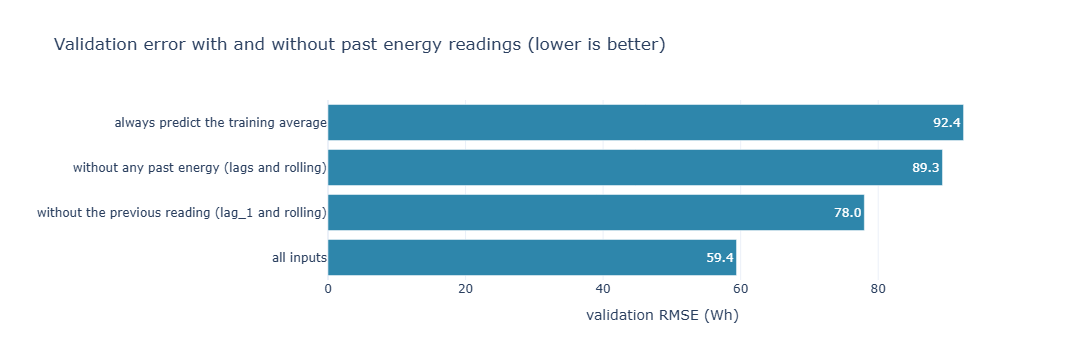

In [50]:
fig = px.bar(lag_test, x='Val_RMSE', y='inputs', orientation='h', text_auto='.1f',
             labels={'Val_RMSE': 'validation RMSE (Wh)', 'inputs': ''},
             title='Validation error with and without past energy readings (lower is better)')
fig.show()

To see how much the model depends on recent energy readings, I trained Lasso (with the tuned alpha) on three sets of inputs and scored each on the same validation rows. With all 49 inputs the validation RMSE is 59.4 Wh (R² 0.59). Without the previous reading (`lag_1` and the rolling features, which contain it) it rises to 78.0 Wh (R² 0.29), and without any past energy it is 89.3 Wh (R² 0.06), only slightly better than always predicting the training average (92.4 Wh); its average miss (MAE 58.4 Wh) is even larger than that of the constant guess (54.1 Wh). So with a linear model, the weather, the time of day and the lights alone explain very little of the energy use, and almost all of the skill comes from recent energy readings. In practice this model is a short-term forecast that needs the latest readings, for example from a smart meter. These results are for Lasso with the alpha tuned for the full model, and I did not test other model types on the reduced inputs.

## Final test evaluation

The test set (the last 20 days, 2,961 readings) is used once here, with the tuned Lasso exactly as it is. The model is not changed after this. As on the validation set, the reference point is the simplest forecast: the previous reading.

In [51]:
test_pred = tuned_model.predict(X_test)
baseline_pred = test_fe['lag_1']       # the previous reading, as on the validation set

final_metrics = calculate_metrics(y_test, test_pred, 'Test_')
baseline_test = calculate_metrics(y_test, baseline_pred, 'Test_')

test_table = pd.DataFrame({f"Lasso (alpha {best_params['alpha']:.3f})": final_metrics,
                           'previous reading (baseline)': baseline_test}).T
test_table[['Test_RMSE', 'Test_MAE', 'Test_MSE', 'Test_R2']].round(3)

,Test_RMSE,Test_MAE,Test_MSE,Test_R2
Lasso (alpha 0.316),60.072,26.795,3608.690,0.563
previous reading (baseline),66.837,26.738,4467.173,0.459


In [52]:
error_df = pd.DataFrame({'Actual': y_test.values, 'Predicted': test_pred,
                         'Error': y_test.values - test_pred})   # positive = predicted too low
error_df['Abs_Error'] = error_df['Error'].abs()
print('mean error (actual - predicted):', round(error_df['Error'].mean(), 1), 'Wh')

error_df['range'] = pd.cut(error_df['Actual'], bins=[0, 50, 100, 175, 300, np.inf],
                           labels=['up to 50', '51-100', '101-175', '176-300', 'over 300'])
by_range = error_df.groupby('range', observed=True).agg(
    readings=('Error', 'size'), mean_error=('Error', 'mean'),
    mean_abs_error=('Abs_Error', 'mean')).round(1)
by_range

mean error (actual - predicted): 1.3 Wh


,readings,mean_error,mean_abs_error
range,,,
up to 50,795,-9.9,11.6
51-100,1537,-6.6,15.9
101-175,351,-11.8,28.3
176-300,148,19.6,62.3
over 300,130,177.5,204.4


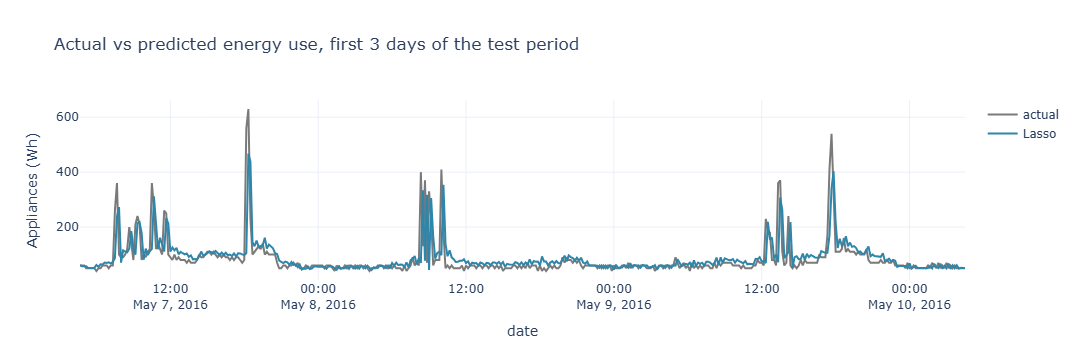

In [53]:
days = 3 * 144
plot_df = pd.DataFrame({'date': test_fe['date'], 'actual': y_test.values,
                        'Lasso': test_pred}).head(days)
fig = px.line(plot_df.melt(id_vars='date'), x='date', y='value', color='variable',
              color_discrete_sequence=['#7A7A7A', '#2E86AB'],
              labels={'value': 'Appliances (Wh)', 'variable': ''},
              title='Actual vs predicted energy use, first 3 days of the test period')
fig.show()

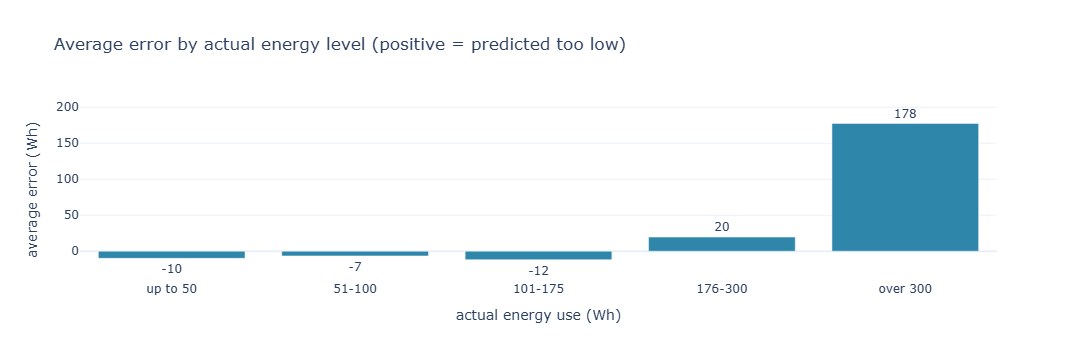

In [54]:
fig = px.bar(by_range.reset_index(), x='range', y='mean_error', text_auto='.0f',
             labels={'range': 'actual energy use (Wh)', 'mean_error': 'average error (Wh)'},
             title='Average error by actual energy level (positive = predicted too low)')
fig.update_traces(textposition='outside', cliponaxis=False)
fig.update_yaxes(range=[-40, 210])
fig.show()

In [55]:
lasso_weeks = backtest[backtest['model'] == 'Lasso (tuned)']
comparison = pd.DataFrame(
    {'RMSE': [final_metrics['Test_RMSE'], lasso_weeks['RMSE'].mean(), lasso_weeks['RMSE'].std()],
     'MAE': [final_metrics['Test_MAE'], lasso_weeks['MAE'].mean(), lasso_weeks['MAE'].std()],
     'R2': [final_metrics['Test_R2'], lasso_weeks['R2'].mean(), lasso_weeks['R2'].std()]},
    index=['test set', 'backtest weekly mean', 'backtest weekly std'])
comparison.round(2)

,RMSE,MAE,R2
test set,60.07,26.80,0.56
backtest weekly mean,63.19,28.13,0.59
backtest weekly std,7.35,3.90,0.03


On the test set (the last 20 days, 2,961 readings) the tuned Lasso reaches an RMSE of 60.1 Wh, an MAE of 26.8 Wh, an MSE of 3,609 Wh² and an R² of 0.56. Copying the previous reading gives 66.8 Wh, 26.7 Wh, 4,467 Wh² and 0.46, so Lasso's RMSE is about 10% lower while the average miss (MAE) is about the same. This is in line with the validation score (59.4 Wh) and close to the weekly backtest average (63.2 Wh, with a weekly spread of about 7 Wh), so the test period does not look unusually easy or hard. On average the predictions are only 1.3 Wh too low, but the error depends on the level of use. For readings up to 175 Wh the model is slightly too high (7 to 12 Wh on average) and typically misses by 12 to 28 Wh. From 176 Wh it starts to be too low (20 Wh on average, typical miss 62 Wh), and for the 130 readings above 300 Wh (about 4% of the test set) it is too low by about 178 Wh on average, with a typical miss of 204 Wh. In the first three days shown in the chart, the model follows the timing and shape of the spikes but does not reach their full height. So the model works well for the usual daily pattern but underestimates the biggest peaks. The test set was used once, and the model was not changed afterwards.

## Saving the model

The model is saved with everything an app needs to use it: the tuned Lasso, the scaler fitted on the training data, the list of the 49 inputs in the right order, the tuned settings and the test scores. The file does not contain the code that builds the inputs (the lag and rolling features, the time features and the indoor averages), so an app has to build them in the same way.

In [56]:
import os
import joblib

model_package = {
    'model': tuned_model,
    'scaler': scaler,
    'feature_names': feature_names,
    'model_name': best_model_name,
    'best_params': best_params,
    'metrics': {'R2': float(final_metrics['Test_R2']), 'MSE': float(final_metrics['Test_MSE']),
                'RMSE': float(final_metrics['Test_RMSE']), 'MAE': float(final_metrics['Test_MAE'])},
}
joblib.dump(model_package, 'final_model.pkl')
print('saved final_model.pkl,', round(os.path.getsize('final_model.pkl') / 1024, 1), 'KB')

# check: reload the file and predict the validation rows from the unscaled features
loaded = joblib.load('final_model.pkl')
rebuilt = loaded['scaler'].transform(val_fe[loaded['feature_names']])
print('reloaded package gives the same predictions:',
      np.allclose(loaded['model'].predict(rebuilt), tuned_model.predict(X_val)))

saved final_model.pkl, 4.2 KB
reloaded package gives the same predictions: True


The saved model is the tuned Lasso trained on the training data only; it was not refitted on the validation or test data. The scores stored in the file are the test scores from the single test evaluation. The check above confirms that the file can be reloaded and gives the same predictions starting from the unscaled features.

## Summary

**Goal:** predict how much energy household appliances use every 10 minutes.

**Data:** 19,735 readings (January to May 2016), split by time into 70% training, 15% validation and 15% test.

**What I did:** built time, indoor-average and past-energy features, then compared a simple baseline (the previous reading), six standard models, ARIMA and an LSTM. Lasso had the lowest validation error, so I tuned it and tested it once.

**Result on the test set:** RMSE 60.1 Wh, MAE 26.8 Wh, R² 0.56. Copying the previous reading gives 66.8 Wh, 26.7 Wh and 0.46.

**Findings:**
- Almost all of the skill comes from recent energy readings. Without them, the model is barely better than guessing the average.
- Energy use is lowest overnight and peaks around 6 pm.
- Simple linear models did as well as the complex ones.

**Limits:**
- The data covers only about 4.5 months.
- The model needs the latest energy readings as input.
- It underestimates the biggest peaks: for readings above 300 Wh it is about 178 Wh too low on average.

## A smaller model for the app

The app cannot ask a household for 49 inputs. The importance results show that only the recent energy readings matter, so the app model uses just the time (5 inputs) and the last 12 readings (2 hours, 11 inputs). I train it the same way as before (scaler and alpha chosen on the training data only) and score it on the validation set. The test set is not used again for this model.

In [57]:
app_features = ['hour', 'dayofweek', 'is_weekend', 'is_night', 'is_peak_hour',
                'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12',
                'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12',
                'rolling_std_6', 'rolling_max_6', 'rolling_min_6']

app_scaler = RobustScaler().fit(train_fe[app_features])
A_train = pd.DataFrame(app_scaler.transform(train_fe[app_features]), columns=app_features)
A_val = pd.DataFrame(app_scaler.transform(val_fe[app_features]), columns=app_features)

app_search = GridSearchCV(Lasso(max_iter=10000), {'alpha': np.logspace(-3, 1, 9)},
                          cv=TimeSeriesSplit(n_splits=5), scoring='neg_root_mean_squared_error')
app_search.fit(A_train, y_train)
app_model = app_search.best_estimator_
print('best alpha:', round(app_search.best_params_['alpha'], 4))

app_val = calculate_metrics(y_val, app_model.predict(A_val), 'Val_')
app_table = pd.DataFrame({'app model (16 inputs)': app_val,
                          'full Lasso (49 inputs)': calculate_metrics(y_val, tuned_model.predict(X_val), 'Val_'),
                          'previous reading (baseline)': baseline}).T
app_table[['Val_RMSE', 'Val_MAE', 'Val_R2']].round(3)

best alpha: 0.1


,Val_RMSE,Val_MAE,Val_R2
app model (16 inputs),59.829,27.132,0.579
full Lasso (49 inputs),59.400,26.704,0.585
previous reading (baseline),66.430,26.162,0.481


In [58]:
joblib.dump({'model': app_model, 'scaler': app_scaler, 'feature_names': app_features,
             'metrics': {'RMSE': float(app_val['Val_RMSE']), 'MAE': float(app_val['Val_MAE']),
                         'R2': float(app_val['Val_R2'])}}, 'app_model.pkl')
print('saved app_model.pkl')

saved app_model.pkl
